# Experimento B completo: sección 4.2 y presupuestos de la sección 4.3

Compara seis helicópteros heterogéneos y siete áreas con el mismo objetivo
multidimensional de A. Cold, Benefit start y Density start reciben cada
uno **1, 5, 15, 60, 600 y 1800 segundos** en búsquedas independientes.
Las tablas 3/4 y figuras B1/B8 usan 1800 s. El punto común de 600 s
permite comparar presupuestos iguales entre A y B.

El modo inicial es **full**: 150 instancias, 2700 optimizaciones y
300 greedy. No hay otra fase de referencia. La carpeta nueva es
`ttap_runs_paper_2000dpi`; `RESUME=True` permite retomar la corrida.
Para una comprobación corta, cambiar `MODE` a `pilot` antes de resolver.


In [1]:
from pathlib import Path
import hashlib, importlib.util, json, subprocess, sys
from urllib.request import urlopen

RUNTIME_REVISION = '2b3a49064ba890f7577e156d793872e9bfc67989'
EXPECTED_SHA256 = {
    "frozen_generator_A.py": "d1eada7a7557203598f165be50b60faa4e9ef5e572bd64327d430848559841a6",
    "frozen_generator_B.py": "c33fbb583bceb3582f968f219abc8f5d1b4c5aaf17fa5ac8801cf66c32570297",
    "frozen_ttap_core.py": "d2d022eaf39cf91ab0d68eba3d95c131a2f90b6408d8e32472e29dc331b114a5",
    "ttap_warm_start.py": "96a9dc50863b7bb41ef34359cf4cf6cd143880cfd14a9970044396620d0405f6",
    "objective_profiles.py": "a655b2368b94b96d366fb3919e4300e0d8715efb5c2c88b2b00bbb8564b0eafe",
    "study_runner.py": "e02a59f2819730de6e728edbf13e02a630839ee6113e57f46060989ae6bf15bd",
    "study_analysis.py": "a673fdece4141fec6de81f98c3e955d962e6d415b71097bd8aec6d57ab3bafc4",
    "figure5_and_analysis.py": "8b611fa972678f051710c89484935a3eb84d26409c694c67e6bddd16f5757321",
    "public_sources.py": "4e1a545646f1ba46bf5a78f0930f39fac318f7ac304fe3874f41c2305ac36f1e",
    "talcahuano_three_methods.py": "ecabb5c3e4ba6af98a35dc4845a840891e0f6b7dacb8bfa0bfdbd44fe1c69d9d",
    "ablation_recovery.py": "e41a7a35efce97ada50c65493d7cafeabc47564e5263a9d8de3de7918331fc97",
    "requirements_execution.txt": "37b0105f36958ae5a61e8b2628f96339e1c9f9eff1306eee3748357d63766876",
    "paper_experiment_a.py": "cccdb79f0db87b3ab78398a5663dbd256e1b3e7a69cf63b3e4d91614fda05b9c",
    "paper_a_report.py": "3337e0ee00e81d01c2778ddc1aad79d3e77afacf95f2d22214d1a246fd69fbdb",
    "paper_experiment_b.py": "9c44ac82fc0becb861e3667c47b6340c27bf87665844489e24cae70778804d68",
    "paper_b_report.py": "eb8603888d572323c8ecf6e877cc1aec774661154707060068d432482ca51b22",
    "paper_clock_report.py": "f93f21bac2a6870ace8cd3c61721e682d7bac971cbc4f6876dbef65279d33165"
}

def _ttap_canonical_bytes(content):
    # Git may check out text with CRLF on Windows. No other text is discarded.
    return content.replace(b'\r\n', b'\n')


def _ttap_prepare_runtime(revision, expected_hashes, *, root=None, opener=None):
    import tempfile

    root = Path.cwd() if root is None else Path(root)
    opener = urlopen if opener is None else opener
    signature = hashlib.sha256(
        json.dumps(expected_hashes, sort_keys=True).encode('utf-8')
    ).hexdigest()[:12]
    runtime = root / ('ttap_runtime_' + revision[:10] + '_' + signature)
    runtime.mkdir(parents=True, exist_ok=True)
    candidates = [root / 'TTAP_WarmStart', root / 'Resuelto_Paper' / 'TTAP_WarmStart',
                  root, root / ('ttap_runtime_' + revision[:10])]
    base = ('https://raw.githubusercontent.com/educarrascov/DISC_TESIS/'
            + revision + '/Resuelto_Paper/TTAP_WarmStart/')
    counts = {'cache': 0, 'local': 0, 'download': 0}

    def matching_bytes(path, expected):
        if not path.is_file():
            return None
        content = _ttap_canonical_bytes(path.read_bytes())
        return content if hashlib.sha256(content).hexdigest() == expected else None

    for name, expected in expected_hashes.items():
        path = runtime / name
        content = matching_bytes(path, expected)
        if content is not None:
            counts['cache'] += 1
            # Files written here always use LF, including a cache copied from Windows.
            if path.read_bytes() == content:
                continue
        else:
            for candidate in candidates:
                content = matching_bytes(candidate / name, expected)
                if content is not None:
                    counts['local'] += 1
                    break
            if content is None:
                try:
                    with opener(base + name, timeout=90) as response:
                        content = _ttap_canonical_bytes(response.read())
                except OSError as exc:
                    raise RuntimeError(
                        'No se pudo descargar ' + name + ' de la revisión ' + revision
                        + '. Comprueba la conexión y vuelve a ejecutar esta celda. '
                        + 'Los archivos de tu proyecto no se han modificado.'
                    ) from exc
                if hashlib.sha256(content).hexdigest() != expected:
                    raise RuntimeError('La descarga no coincide con la revisión fijada: '
                                       + name + '. No se ejecutará ese archivo.')
                counts['download'] += 1

        temporary = None
        try:
            with tempfile.NamedTemporaryFile(dir=runtime, prefix=name + '.',
                                             suffix='.tmp', delete=False) as handle:
                temporary = Path(handle.name)
                handle.write(content)
            temporary.replace(path)
        finally:
            if temporary is not None and temporary.exists():
                temporary.unlink()

    print('Fuentes verificadas:', counts)
    return runtime.resolve()


RUNTIME = _ttap_prepare_runtime(RUNTIME_REVISION, EXPECTED_SHA256)
for name in EXPECTED_SHA256:
    if not name.endswith('.py'):
        continue
    loaded = sys.modules.get(name[:-3])
    if loaded is not None:
        location = getattr(loaded, '__file__', None)
        if location is None or Path(location).resolve() != RUNTIME / name:
            raise RuntimeError(
                'Hay módulos TTAP de otra carpeta cargados en memoria. '
                'Reinicia el kernel (Kernel > Restart) y ejecuta desde la primera celda.'
            )


missing_science = [m for m in ['numpy', 'scipy', 'pandas', 'matplotlib']
                   if importlib.util.find_spec(m) is None]
if missing_science:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-r', str(RUNTIME / 'requirements_execution.txt')], check=True)
elif importlib.util.find_spec('highspy') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'highspy==1.11.0'], check=True)
sys.path.insert(0, str(RUNTIME))
import highspy
if highspy.Highs().version() != '1.11.0':
    raise RuntimeError('Use highspy==1.11.0 and restart the kernel before the study.')
from IPython.display import display, Image, SVG
from objective_profiles import ObjectiveSpec, professor_examples
from paper_experiment_b import paper_b_configuration, run_paper_experiment_b
from paper_b_report import export_paper_b
print('Verified runtime:', RUNTIME_REVISION)
print('Local modules:', RUNTIME)
print('Experiment B paper protocol: 1 / 5 / 15 / 60 / 600 / 1800 s for all three starts')


Fuentes verificadas: {'cache': 17, 'local': 0, 'download': 0}
Verified runtime: 2b3a49064ba890f7577e156d793872e9bfc67989
Local modules: /Users/educarrascovidal/Documentos/GitHub/Tesis_Doctoral/DISC_TESIS/Resuelto_Paper/ttap_runtime_2b3a49064b_76417531d969
Experiment B paper protocol: 1 / 5 / 15 / 60 / 600 / 1800 s for all three starts


## Objetivo y configuración

`multidimensional` suma outputs distintos: pacientes, pasajeros no médicos y cargo.
El término de personas excluye a los pacientes y el de carga excluye peso corporal
o equipo usado sólo como apoyo. Con referencias fijas, el valor potencial es
\(\phi_i=\lambda_m m_i/R_m+\lambda_p p_i/R_p+\lambda_q q_i/R_q\).
Los pesos son compensatorios; no imponen precedencia médica absoluta.

La carpeta nueva `B_paper_...` se mantiene separada de las corridas anteriores de
cuatro presupuestos. Para reanudarla, conservar configuración, fuentes y entorno.


In [2]:
MODE = 'full'  # 'pilot': 20 tareas/semilla 1; 'screen': 9 instancias; 'full': 150
OBJECTIVE_MODE = 'primary'
WEIGHTS = {'medical': 2.0, 'personnel': 1.5, 'cargo': 1.0}
REFERENCES = {'medical': 3.0, 'personnel': 3.0, 'cargo': 500.0}
OUTPUT_ROOT = Path.cwd() / 'ttap_runs_paper_2000dpi'  # Usar almacenamiento persistente.
RESUME = True
PNG_DPI = 2000  # Estándar del notebook original: PNG 2000 dpi y PDF/SVG vectoriales.

spec = ObjectiveSpec(OBJECTIVE_MODE, WEIGHTS, REFERENCES)
config = paper_b_configuration(MODE, spec)
RUN_DIR = OUTPUT_ROOT / ('B_paper_' + MODE + '_' + config.fingerprint[:12])
print('Objective:', spec.as_dict())
print('Configuration:', config.as_dict())
print('Output:', RUN_DIR)
print('Workload:', config.workload())
print('Cold 600/1800 s is included; no additional reference phase will run.')
if spec.mode == 'multidimensional':
    print('Illustrative potential values:', professor_examples(spec))


Objective: {'schema': 'ttap-value-v2', 'mode': 'primary', 'weights': {'medical': 2.0, 'personnel': 1.5, 'cargo': 1.0}, 'references': {'medical': 3.0, 'personnel': 3.0, 'cargo': 500.0}, 'semantics': 'one-primary-output-with-auxiliary-resource-requirements'}
Configuration: {'experiment': 'B', 'tasks': [20, 30, 40, 50, 60], 'seeds': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30], 'budgets': [1.0, 5.0, 15.0, 60.0, 600.0, 1800.0], 'reference_budgets': [], 'objective': {'schema': 'ttap-value-v2', 'mode': 'primary', 'weights': {'medical': 2.0, 'personnel': 1.5, 'cargo': 1.0}, 'references': {'medical': 3.0, 'personnel': 3.0, 'cargo': 500.0}, 'semantics': 'one-primary-output-with-auxiliary-resource-requirements'}, 'threads': 1, 'solver_seed': 0, 'mip_rel_gap': 1e-06, 'trace': True, 'paper_protocol': 'TTAP-B-paper-six-budgets-v1', 'paper_runner_sha256': '9c44ac82fc0becb861e3667c47b6340c27bf87665844489e24cae70778804d68'}
Output: /Us

## Ejecutar el experimento

Los starts se convierten en vectores binarios completos y se validan antes de
entregarlos a HiGHS, sin fijar variables. La ejecución usa el generador y MILP
originales con el objetivo seleccionado. Se guarda un checkpoint después de
cada job; volver a ejecutar con `RESUME=True` omite los que ya terminaron.

En full, la suma de presupuestos es **310 h 7 min 30 s**. No es una predicción
del tiempo real: una búsqueda termina antes si certifica, y la preparación y los
excesos del límite agregan tiempo. Mantener el equipo conectado y sin suspensión.


In [3]:
results = run_paper_experiment_b(config, RUN_DIR, resume=RESUME)
cols = ['Scenario', 'Method', 'Normalized Mission Value', 'Warm Start Submitted',
        'Warm Start Value', 'Solver Has Incumbent', 'Optimal Certified', 'End-to-end sec']
print('Completed metric rows:', len(results), '| expected:', config.workload()['expected_metric_rows'])
display(results[[c for c in cols if c in results]].tail(17))


B6x7_stress_T20_S1: build primary MILP (warm)
  217,540 variables; 71,293 constraints
  HiGHS-1s-GBStart: value=0.621891; solver plan=True; certified=False
  HiGHS-1s-GDStart: value=0.683246; solver plan=True; certified=False
  HiGHS-1s-Cold: value=nan; solver plan=False; certified=False
  HiGHS-5s-GBStart: value=0.621891; solver plan=True; certified=False
  HiGHS-5s-GDStart: value=0.683246; solver plan=True; certified=False
  HiGHS-5s-Cold: value=nan; solver plan=False; certified=False
  HiGHS-15s-GBStart: value=0.621891; solver plan=True; certified=False
  HiGHS-15s-GDStart: value=0.683246; solver plan=True; certified=False
  HiGHS-15s-Cold: value=nan; solver plan=False; certified=False
  HiGHS-60s-GBStart: value=0.621891; solver plan=True; certified=False
  HiGHS-60s-GDStart: value=0.683246; solver plan=True; certified=False
  HiGHS-60s-Cold: value=0.000000; solver plan=True; certified=False
  HiGHS-600s-GBStart: value=0.742863; solver plan=True; certified=True
  HiGHS-600s-GDStart:

,Scenario,Method,Normalized Mission Value,Warm Start Submitted,Warm Start Value,Solver Has Incumbent,Optimal Certified,End-to-end sec
2983,B6x7_stress_T60_S9,HiGHS-1s-GBStart,0.266105,True,0.266105,True,False,5.775578
2984,B6x7_stress_T60_S9,HiGHS-1s-GDStart,0.269614,True,0.269614,True,False,5.752871
2985,B6x7_stress_T60_S9,HiGHS-5s-Cold,NaN,False,NaN,False,False,9.548066
2986,B6x7_stress_T60_S9,HiGHS-5s-GBStart,0.266105,True,0.266105,True,False,9.634809
2987,B6x7_stress_T60_S9,HiGHS-5s-GDStart,0.269614,True,0.269614,True,False,9.715253
2988,B6x7_stress_T60_S9,HiGHS-15s-Cold,NaN,False,NaN,False,False,19.744287
2989,B6x7_stress_T60_S9,HiGHS-15s-GBStart,0.266105,True,0.266105,True,False,20.109039
2990,B6x7_stress_T60_S9,HiGHS-15s-GDStart,0.269614,True,0.269614,True,False,19.944507
2991,B6x7_stress_T60_S9,HiGHS-60s-Cold,NaN,False,NaN,False,False,65.405689
2992,B6x7_stress_T60_S9,HiGHS-60s-GBStart,0.266105,True,0.266105,True,False,65.899370


## Exportar la sección 4.2

La validación exige 18 búsquedas y dos greedy por instancia, sin duplicados.
Full genera las tablas 3/4, B1/B8 y `Section_4_2.tex`. El piloto genera
archivos con marca visible y no crea una sección definitiva.

Las medias de calidad usan todas las instancias, incluidos incumbents
sin certificado. Las brechas usan sólo óptimos certificados, con sus
denominadores. Un mejor valor conocido sin prueba no se llama óptimo.
El notebook muestra SVG; en Overleaf usar PDF. Reexportar no optimiza.


,Tasks,Paper method,benefit_mean,benefit_sd,tasks_mean,certified,n,shortfall_mean_pct
0,20,Cold,0.758096,0.055891,18.600000,30,30,0.000000e+00
1,20,GBStart,0.758096,0.055891,18.600000,30,30,4.151659e-16
2,20,GDStart,0.758096,0.055891,18.600000,30,30,4.151659e-16
3,20,GreedyBenefit,0.668065,0.054923,17.566667,0,30,1.188130e+01
4,20,GreedyDensity,0.661121,0.052253,17.733333,0,30,1.276444e+01
5,30,Cold,0.612190,0.052269,23.333333,30,30,0.000000e+00
6,30,GBStart,0.612190,0.052269,23.333333,30,30,0.000000e+00
7,30,GDStart,0.612190,0.052269,23.333333,30,30,5.251054e-16
8,30,GreedyBenefit,0.525654,0.049965,21.400000,0,30,1.410475e+01
9,30,GreedyDensity,0.520765,0.051723,22.333333,0,30,1.495148e+01


Export metadata: {'full_cohort': True, 'experiment': 'B', 'benchmark_budget_sec': 1800.0, 'solver_budgets_sec': [1.0, 5.0, 15.0, 60.0, 600.0, 1800.0], 'instances': 150, 'solver_runs': 2700, 'heuristic_runs': 300, 'known_certified_optima': 116, 'coincident_certified_MILP_curves': False, 'objective': {'schema': 'ttap-value-v2', 'mode': 'primary', 'weights': {'medical': 2.0, 'personnel': 1.5, 'cargo': 1.0}, 'references': {'medical': 3.0, 'personnel': 3.0, 'cargo': 500.0}, 'semantics': 'one-primary-output-with-auxiliary-resource-requirements'}, 'png_dpi': 2000, 'graphics_version': '20261029.3-paper-2000dpi', 'vector_formats': ['pdf', 'svg'], 'figure_sizes_inches': {'quality': (3.5, 2.35), 'effort': (7.2, 3.15), 'budget_by_task': (7.2, 2.65), 'attribution': (7.2, 2.8), 'budget_overview': (7.2, 2.8)}, 'raw_metrics_sha256': 'fd437c7e7d85a91abcdc2a70153efe0ee5dc0ff9ccadf00ad162224eebd8ee68', 'run_manifest_sha256': '26e09639a7396a5954f73620ddc4bae2ba315ec997dcb21f538326ea76177d00', 'data_interp

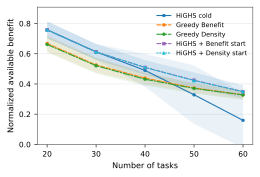

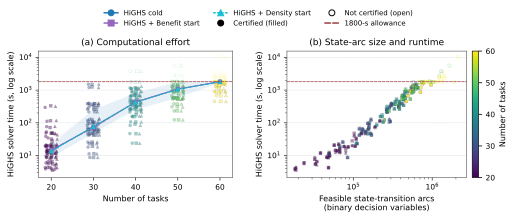

In [4]:
report = export_paper_b(RUN_DIR, png_dpi=PNG_DPI, allow_pilot=(MODE != 'full'))
PAPER_DIR = report['directory']
display(report['quality'][['Tasks', 'Paper method', 'benefit_mean', 'benefit_sd',
                           'tasks_mean', 'certified', 'n', 'shortfall_mean_pct']])
print('Export metadata:', report['metadata'])
print('Output files:', PAPER_DIR)
for name in ['B1_solution_quality_coverage_aware', 'B8_computational_effort']:
    display(SVG(filename=str(PAPER_DIR / (name + '.svg'))))


## Calidad disponible y certificación por presupuesto

B3 y B9-B12 usan el diseño por tamaño de tareas, con los seis presupuestos.
Los CSV incluyen factibilidad devuelta por HiGHS, media y mediana del incumbent,
su distancia al óptimo conocido y los denominadores de cada media. Un incumbent
ausente sigue ausente; no se presenta como una solución devuelta de valor cero.

La Tabla 1 puntúa por separado el plan idle disponible como cero si cold no
devuelve solución. La certificación y la mejora de inyectar el greedy se calculan
por separado. Las curvas por presupuesto son reinicios independientes, no una
única trayectoria anytime. Los óptimos desconocidos quedan desconocidos.

B10/B11 excluyen incumbents ausentes. Los puntos de muestra parcial indican
sus denominadores; acompañar B11 con B9. B12 expresa la ganancia de
inyección en puntos porcentuales y preserva pérdidas. B13 reúne las
tres métricas de Pedro por límite nominal. B14 usa el reloj observado
dentro de las corridas de 1800 s; excluye preparación y no une reinicios.


In [5]:
display(report['budget_quality'])
display(report['attribution'])
SHOW_BUDGET_PLOTS = False
names = ['B3_certification_by_tasks_and_budget', 'B9_budget_feasibility',
         'B10_budget_incumbent_value', 'B11_budget_optimality_shortfall',
         'B12_warm_start_attribution', 'B13_budget_quality_overview', 'B14_observed_anytime_quality']
for name in names:
    print(PAPER_DIR / (name + '.pdf'))
    if SHOW_BUDGET_PLOTS:
        display(SVG(filename=str(PAPER_DIR / (name + '.svg'))))


,Configuration,Tasks,Start Method,Time Limit sec,n,solver_incumbents,available_plans,certified,mean_solver_incumbent,median_solver_incumbent,mean_available_value,n_known_optima,n_known_incumbent_gaps,mean_solver_shortfall_pct,median_solver_shortfall_pct,mean_available_shortfall_pct,mean_measured_seconds,solver_incumbents_pct,available_plans_pct,certified_pct
0,B,20,Cold,1.0,30,0,0,0,NaN,NaN,0.000000,30,0,NaN,NaN,100.000000,1.930117,0.000000,0.000000,0.000000
1,B,20,Cold,5.0,30,5,5,3,0.655385,0.706256,0.109231,30,5,9.669044e+00,1.514862e-14,84.944841,6.121289,16.666667,16.666667,10.000000
2,B,20,Cold,15.0,30,24,24,16,0.666438,0.715913,0.533150,30,24,1.106810e+01,6.537775e-15,28.854479,14.710757,80.000000,80.000000,53.333333
3,B,20,Cold,60.0,30,29,29,27,0.726019,0.732887,0.701818,30,29,3.973450e+00,0.000000e+00,7.174335,27.737952,96.666667,96.666667,90.000000
4,B,20,Cold,600.0,30,30,30,30,0.758096,0.759696,0.758096,30,30,3.689360e-15,0.000000e+00,0.000000,31.905635,100.000000,100.000000,100.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,B,60,GDStart,5.0,30,30,30,0,0.327588,0.335352,0.327588,9,9,1.768459e+01,1.735895e+01,17.684586,14.326661,100.000000,100.000000,0.000000
86,B,60,GDStart,15.0,30,30,30,0,0.327588,0.335352,0.327588,9,9,1.768459e+01,1.735895e+01,17.684586,24.849359,100.000000,100.000000,0.000000
87,B,60,GDStart,60.0,30,30,30,0,0.327588,0.335352,0.327588,9,9,1.768459e+01,1.735895e+01,17.684586,81.304947,100.000000,100.000000,0.000000
88,B,60,GDStart,600.0,30,30,30,1,0.331734,0.337178,0.331734,9,9,1.369317e+01,1.526639e+01,13.693170,1516.681981,100.000000,100.000000,3.333333


,Configuration,Tasks,Start Method,Time Limit sec,n,mean_gain_over_greedy,median_gain_over_greedy,mean_injection_gain,median_injection_gain,improved_greedy,beat_cold_plus_greedy
0,B,20,GBStart,1.0,30,0.000000,0.000000,0.000000e+00,0.0,0,0
1,B,20,GBStart,5.0,30,0.011190,0.000000,1.277059e-04,0.0,4,1
2,B,20,GBStart,15.0,30,0.047588,0.059454,-3.183856e-03,0.0,20,1
3,B,20,GBStart,60.0,30,0.079488,0.078182,-3.700743e-18,0.0,27,0
4,B,20,GBStart,600.0,30,0.090031,0.086083,-3.700743e-18,0.0,30,0
5,B,20,GBStart,1800.0,30,0.090031,0.086083,-3.700743e-18,0.0,30,0
6,B,20,GDStart,1.0,30,0.000000,0.000000,0.000000e+00,0.0,0,0
7,B,20,GDStart,5.0,30,0.009454,0.000000,5.616411e-04,0.0,4,1
8,B,20,GDStart,15.0,30,0.054752,0.065962,1.992481e-04,0.0,21,2
9,B,20,GDStart,60.0,30,0.087670,0.087904,-3.700743e-18,0.0,28,0


/Users/educarrascovidal/Documentos/GitHub/Tesis_Doctoral/DISC_TESIS/Resuelto_Paper/ttap_runs_paper_2000dpi/B_paper_full_a1dfd983cde0/paper/B3_certification_by_tasks_and_budget.pdf
/Users/educarrascovidal/Documentos/GitHub/Tesis_Doctoral/DISC_TESIS/Resuelto_Paper/ttap_runs_paper_2000dpi/B_paper_full_a1dfd983cde0/paper/B9_budget_feasibility.pdf
/Users/educarrascovidal/Documentos/GitHub/Tesis_Doctoral/DISC_TESIS/Resuelto_Paper/ttap_runs_paper_2000dpi/B_paper_full_a1dfd983cde0/paper/B10_budget_incumbent_value.pdf
/Users/educarrascovidal/Documentos/GitHub/Tesis_Doctoral/DISC_TESIS/Resuelto_Paper/ttap_runs_paper_2000dpi/B_paper_full_a1dfd983cde0/paper/B11_budget_optimality_shortfall.pdf
/Users/educarrascovidal/Documentos/GitHub/Tesis_Doctoral/DISC_TESIS/Resuelto_Paper/ttap_runs_paper_2000dpi/B_paper_full_a1dfd983cde0/paper/B12_warm_start_attribution.pdf
/Users/educarrascovidal/Documentos/GitHub/Tesis_Doctoral/DISC_TESIS/Resuelto_Paper/ttap_runs_paper_2000dpi/B_paper_full_a1dfd983cde0/paper/B

## Integrar la sección 4.2 en Overleaf

Después de full, subir los dos PDF principales y los .tex de `paper`. Se necesitan
`booktabs`, `makecell` y `graphicx`. `Section_4_2.tex` incluye ambas tablas y figuras
y redacta un texto breve a partir de la corrida, sin asumir mejoras del warm start.
Revisar la interpretación y los nombres de labels antes de sustituir el texto.

Actualizar también el componente de impacto de la sección 3.3 y los numeradores
de ambos greedy, conservando la función temporal. Antes de presentar A, B y
Talcahuano juntos, sus resultados deben usar la misma definición de beneficio.


In [ ]:
for name in ['Table_3_Experiment_B_quality.tex', 'Table_4_Experiment_B_runtime.tex',
             'Section_3_3_impact_update.tex', 'OVERLEAF_README.txt']:
    print(PAPER_DIR / name)
if report['metadata']['full_cohort']:
    print('Section replacement:', PAPER_DIR / 'Section_4_2.tex')
else:
    print('Pilot only: Section_4_2.tex is deliberately not generated.')
